In [64]:
import numpy as np
import sys
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
np.set_printoptions(threshold=sys.maxsize, precision=2, suppress=True)

0  - Pronghorn \
1  - Coyote \
2  - Small Mammals \
3  - Elk \
4  - Woody Plants \
5  - Stream Morphology \
6  - Beaver \
7  - Birds \
8  - Berries \
9 - Bear \
10 - Scavengers \
11 - Wolf

In [80]:
species = {
    0 : 'Pronghorn',
    1 : 'Coyote',
    2 : 'Small Mammals',
    3 : 'Elk',
    4 : 'Woody Plants',
    5 : 'Stream Morphology',
    6 : 'Beaver',
    7 : 'Birds',
    8 : 'Berries',
    9: 'Bear',
    10: 'Scavengers',
    11: 'Wolf'
}

In [ ]:

def interaction_matrix(N):
    int_mat = np.zeros((N, N))

    #Pronghorn
    int_mat[0, 1] = 1 #Coyote

    #Coyote
    int_mat[1, 0] = -1 #Pronghorn
    int_mat[1, 2] = -1 #Small Mammals
    int_mat[1, 3] = -1 #Elk

    #Small Mammals
    int_mat[2, 1] = 1 #Coyote

    #Elk
    int_mat[3, 1] = 1 #Coyote
    int_mat[3, 4] = -1 #Woody Plants
    int_mat[3, 9] = 1 #Bear
    int_mat[3, 10] = 1 #Scavengers
    int_mat[3, 11] = 1 #Wolf

    #Woody Plants
    int_mat[4, 3] = 1 #Elk
    int_mat[4, 5] = 1 #Stream Morphology
    int_mat[4, 6] = 1 #Beaver
    int_mat[4, 7] = 1 #Birds
    int_mat[4, 8] = 1 #Berries

    #Berries
    int_mat[8, 9] = 1 #Bear

    #Bear
    int_mat[9, 3] = -1 #Elk
    int_mat[9, 4] = 1 #Woody Plants

    #Wolf
    int_mat[11, 1] = -1 #Coyote
    int_mat[11, 3] = -1 #Elk

    return int_mat.T #Returning the transpose because I constructed this wrong


In [191]:
def A_matrix(int_mat, N):

    #a_i,i < 0
    A = int_mat - np.identity(N)

    #Interaction in uniform distribution
    A = np.multiply(A, np.random.uniform(size=A.shape))

    #Predator-prey special case
    for i in np.arange(N):
        for j in np.arange(N):
            if int_mat[i, j] == 1 and int_mat[j, i] == -1:
                A[i, j] = np.random.uniform(0, -0.2*A[j, i])
            
    return A

def r_vec_known():
    #r_known[0] = Wolf
    #r_known[1] = Elk
    #r_known[2] = Bear
    r_known = np.array([1.29, 0.18, 0.045])

    for i in np.arange(len(r_known)):
        r_known[i] = np.random.lognormal(r_known[i], 0.5) 

    return r_known

def r_vec(N):

    #Generate known rates
    r_known = r_vec_known()

    #Sample unkown rates
    r_max = np.max(r_known)
    r = np.random.uniform(0, r_max, size=N)
    
    #Set known rates
    r[3] = r_known[1] #Elk
    r[9] = r_known[2] #Bear
    r[11] = r_known[0] #Wolf

    return r


def jacobian(A, r, n, N):

    #Compute Jacobian as defined in the paper
    J = np.multiply(A, n)
    diag = r + A@n
    J += diag * np.identity(N)

    return J

def check_positive(x):

    #Return true iff all values are positive
    for i in np.arange(len(x)):
        if x[i] <= 0:
            return False
        
    return True

def viable(A, r, n_eq, N):
    
    #Check if equilibrium populations are positive
    if check_positive(n_eq):

        #Equilibria must be stable
        #(Real part of eigenvalues of the Jacobian are negative)
        J_eq = jacobian(A, r, n_eq, N) 
        eig_val, eig_vec = np.linalg.eig(J_eq)
        return check_positive(-eig_val.real)
    
    return False

def introduce_species(n):

    #Initial population of introduced species  = 10% of smallest population
    new_pop = 0.1*np.min(n)
    return np.concatenate((n, [new_pop]))

def generate_viable_models(M):

    #Get matrix of interaction network
    N=12
    int_mat = interaction_matrix(N)

    #Initialize arrays for parameters and equilibrium populations
    As = np.zeros((M, N, N))
    rs = np.zeros((M, N))
    ns = np.zeros((M, N))

    #Generate M viable models
    i = 0 #Index of viable models
    j = 0 #Overall index
    while i < M:

        #Generate parameters
        A = A_matrix(int_mat, N)
        r = r_vec(N)

        #Calculate equilibria without wolf
        A_init = A[0:N-1, 0:N-1]
        r_init = r[0:N-1]
        n_eq = -np.linalg.inv(A_init)@r_init

        #Store parameters if viable
        if viable(A_init, r_init,n_eq, N-1):
            As[i] = A
            rs[i] = r
            ns[i] = introduce_species(n_eq) #Introduced species is added here
            i += 1

        j += 1
    print(f'total iterations: {j}')
    return As, rs, ns

#Rate equation
def mod_lot_vol(t, n, A, r):
    return np.multiply(r, n) + np.multiply(A@n, n)


def simulate_eem(As, rs, ns_init, M, N):
    dt = 0.1
    t_max = 30
    t_eval = np.arange(0, t_max, dt)
    ns = np.zeros((M, len(t_eval), N))

    for i in np.arange(M):
        sol = solve_ivp(mod_lot_vol, (0, t_max), ns_init[i], t_eval=t_eval, args=(As[i], rs[i]))
        ns[i] = np.transpose(sol.y)
        if i % 100 == 0:
            print(i)

    return t_eval, ns



In [193]:

M = 100
N = 12
As, rs, ns_init = generate_viable_models(M)
ts, ns = simulate_eem(As, rs, ns_init, M, N)






total iterations: 4600
0


Text(0, 0.5, 'Relative Population size')

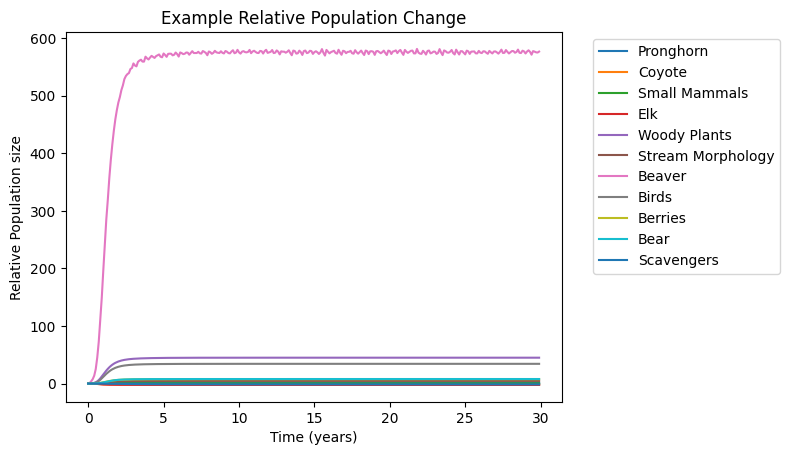

In [194]:
m = 12
for i in np.arange(N-1):
    plt.plot(ts, ns[m, :, i]-ns_init[m, i], label=species[i])

plt.legend(bbox_to_anchor=(1.05, 1.0), loc='upper left')
plt.title('Example Relative Population Change')
plt.xlabel('Time (years)')
plt.ylabel('Relative Population size')

In [195]:
diff = ns[:,-1] - ns_init
counts = np.zeros(N)
elk_increase_counts = np.zeros(N)
elk_decrease_counts = np.zeros(N)
elk_increase = False
for i in np.arange(M):
    elk_increase = diff[i, 3] > 0
    for j in np.arange(N):
        if diff[i,j] > 0:
            counts[j] += 1
            if elk_increase:
                elk_increase_counts[j] += 1
            else:
                elk_decrease_counts[j] += 1
    

props = counts / M
elk_increase_props = elk_increase_counts/counts[3]
elk_decrease_props = elk_decrease_counts/(M-counts[3])

print('Proportion of models with increased populations:')
for i in np.arange(N):
    print(species[i] + f': {props[i]}, {elk_increase_props[i]}, {elk_decrease_props[i]}')



Proportion of models with increased populations:
Pronghorn: 1.0, 1.0, 1.0
Coyote: 0.0, 0.0, 0.0
Small Mammals: 1.0, 1.0, 1.0
Elk: 0.1, 1.0, 0.0
Woody Plants: 0.9, 0.0, 1.0
Stream Morphology: 0.89, 0.0, 0.9888888888888889
Beaver: 0.9, 0.0, 1.0
Birds: 0.9, 0.0, 1.0
Berries: 0.9, 0.0, 1.0
Bear: 0.77, 0.4, 0.8111111111111111
Scavengers: 0.1, 1.0, 0.0
Wolf: 1.0, 1.0, 1.0


In [175]:
N=12
int_mat = interaction_matrix(N)
A = A_matrix(int_mat, N)
r = r_vec(N)

print(int_mat)
print(A)
print(r)

[[ 0. -1.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.]
 [ 1.  0.  1.  1.  0.  0.  0.  0.  0.  0.  0. -1.]
 [ 0. -1.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.]
 [ 0. -1.  0.  0.  1.  0.  0.  0.  0. -1.  0. -1.]
 [ 0.  0.  0. -1.  0.  0.  0.  0.  0.  1.  0.  0.]
 [ 0.  0.  0.  0.  1.  0.  0.  0.  0.  0.  0.  0.]
 [ 0.  0.  0.  0.  1.  0.  0.  0.  0.  0.  0.  0.]
 [ 0.  0.  0.  0.  1.  0.  0.  0.  0.  0.  0.  0.]
 [ 0.  0.  0.  0.  1.  0.  0.  0.  0.  0.  0.  0.]
 [ 0.  0.  0.  1.  0.  0.  0.  0.  1.  0.  0.  0.]
 [ 0.  0.  0.  1.  0.  0.  0.  0.  0.  0.  0.  0.]
 [ 0.  0.  0.  1.  0.  0.  0.  0.  0.  0.  0.  0.]]
[[-0.41 -0.78  0.    0.    0.    0.    0.    0.    0.    0.    0.    0.  ]
 [ 0.13 -0.9   0.07  0.13  0.    0.    0.    0.    0.    0.    0.   -0.42]
 [ 0.   -0.81 -0.17  0.    0.    0.    0.    0.    0.    0.    0.    0.  ]
 [ 0.   -0.8   0.   -0.14  0.12  0.    0.    0.    0.   -0.02  0.   -0.23]
 [ 0.    0.    0.   -0.92 -0.27  0.    0.    0.    0.    0.46  0.    0.  ]
 [ 0.    0. 